# Lab 7b — LoRA : adapter un LLM sans le réentraîner

**ENSIM · 5A ASTRE · De l'IA au LLM agentique · Séance 7**
*Bassem Ben Hamed & Ali Khalfallah*

Ce lab est **à rejouer après le cours**, en autonomie. Il valide la partie « fine-tuning » de la séance 7 : on code **LoRA de zéro**, on refait l'exemple $2\times2$ des diapositives, puis on fine-tune **Qwen3-1.7B** avec la bibliothèque `peft` sur le fil rouge B (MASSIVE fr-FR, intentions `iot_*`), et on compare au **zero-shot** du même modèle, sur les mêmes commandes de test.

## Objectifs

À la fin du lab, vous savez :

1. compter les paramètres d'une mise à jour **LoRA** et les comparer au fine-tuning complet ;
2. calculer à la main $W' = W + \frac{\alpha}{r}BA$, vérifier que les chemins « fusionné » et « adaptateur » donnent le même résultat, et expliquer pourquoi $B$ est initialisé à zéro ;
3. coder une couche `LoRALinear` en PyTorch et la brancher sur un modèle ;
4. estimer la mémoire de l'entraînement : complet, LoRA, QLoRA ;
5. fine-tuner un LLM avec `peft` pour produire une sortie **JSON `{intent, slots}`** et mesurer ce que cela change : exactitude, JSON valide, longueur du prompt ;
6. reconnaître ce que LoRA **fait bien** (format, vocabulaire d'étiquettes, style) et ce qu'il ne fait pas (injecter des connaissances).

## Prérequis et environnement

- Séances 3 et 6 (rétropropagation, LLM). Notions de PyTorch.
- **Google Colab gratuit, GPU T4** recommandé. Le code choisit le périphérique dans l'ordre CUDA, MPS, CPU. Sur CPU, l'entraînement est réduit à 96 exemples. Les poids sont chargés en **float32** (6,9 Go) pour simplifier l'entraînement. Durée d'exécution : environ 12 minutes sur un Mac M4 Pro (GPU MPS, modèle déjà téléchargé), dont 8 pour l'entraînement ; non mesurée sur un T4.
- `peft` est installé à la demande.

## Plan

| Partie | Contenu |
|---|---|
| 1 | Rappel des formules |
| A | Recalculer les exemples numériques des diapositives |
| B | Expériences : LoRA de zéro, mémoire, fine-tuning `peft` sur MASSIVE, comparaison au zero-shot |
| C | Exercices de validation, vérifiés automatiquement |
| | Corrigé |

> **Données** : *Amazon MASSIVE 1.1*, partition fr-FR (FitzGerald et al., 2022), licence CC BY 4.0. Partitions officielles, restreintes aux **9 intentions `iot_*`** : `train` (769 commandes) pour entraîner, `dev` (118) pour surveiller, `test` (220) pour évaluer.

## 1. Rappel des formules

| Notion | Formule |
|---|---|
| LoRA | $W' = W + \dfrac{\alpha}{r}\,BA$, avec $W \in \mathbb{R}^{d\times k}$, $B \in \mathbb{R}^{d\times r}$, $A \in \mathbb{R}^{r\times k}$ |
| Paramètres | LoRA : $r\,(d+k)$ ; complet : $d \times k$ |
| Passage avant | $\mathbf{h} = W\mathbf{x} + \dfrac{\alpha}{r}\,B\,(A\mathbf{x})$ |
| Gradients | $\dfrac{\partial\mathcal{L}}{\partial B} = \dfrac{\alpha}{r}\,\boldsymbol{\delta}\,(A\mathbf{x})^{\top}$, $\;\dfrac{\partial\mathcal{L}}{\partial A} = \dfrac{\alpha}{r}\,(B^{\top}\boldsymbol{\delta})\,\mathbf{x}^{\top}$ |
| Initialisation | $A$ aléatoire, $B = 0$ : au départ $W' = W$ |
| Mémoire d'entraînement complet (Adam) | 16 octets par paramètre (poids et gradients bf16, copie fp32, deux moments fp32) |
| QLoRA | poids en 4 bits (0,5 octet) + constantes (0,127 bit) + adaptateurs |

### Installation et imports

In [1]:
try:
    import peft
except ImportError:
    %pip install -q peft
    import peft
from peft import LoraConfig, get_peft_model

import collections, io, json, math, os, random, re, shutil, tarfile, tempfile, time, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
T0 = time.time()
CACHE = os.path.join(tempfile.gettempdir(), "lab7b_cache")   # téléchargements, hors du dossier du notebook
os.makedirs(CACHE, exist_ok=True)

def choisir_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")
DEVICE = choisir_device()
print("torch", torch.__version__, "| peft", peft.__version__, "| périphérique :", DEVICE)

torch 2.10.0 | peft 0.22.0 | périphérique : mps


## Partie A — Recalculer les exemples des diapositives

### A1. Combien de paramètres ?

Une matrice $4\,096 \times 4\,096$ (taille d'une projection d'un modèle de 7 B), rang $r = 8$.

In [2]:
d = k = 4096; r = 8
lora, complet = r * (d + k), d * k
print(f"LoRA : r (d + k) = {r} x {d + k} = {lora:,} paramètres".replace(",", " "))
print(f"Complet : d x k = {d}^2 = {complet:,}".replace(",", " "))
print(f"Rapport : {100 * lora / complet:.3f} %")

LoRA : r (d + k) = 8 x 8192 = 65 536 paramètres
Complet : d x k = 4096^2 = 16 777 216
Rapport : 0.391 %


### A2. LoRA à la main : un exemple $2 \times 2$

$r = 1$, $\alpha = 2$, donc $\alpha / r = 2$.

In [3]:
W = np.array([[2.0, 0.0], [1.0, 3.0]])
B = np.array([[1.0], [2.0]])
A = np.array([[0.5, -1.0]])
alpha, r = 2.0, 1
BA = B @ A
print("BA =\n", BA, "\n(alpha/r) BA =\n", (alpha / r) * BA)
Wp = W + (alpha / r) * BA
print("W' = W + (alpha/r) BA =\n", Wp)
print("rang de BA :", np.linalg.matrix_rank(BA), "| paramètres B + A :", B.size + A.size, "| paramètres W :", W.size)

x = np.array([1.0, 1.0])
h_fusion = Wp @ x
Ax = A @ x
h_adapt = W @ x + (alpha / r) * (B @ Ax)
print(f"\nx = {x}: W'x = {h_fusion} (fusionné)")
print(f"W x = {W @ x} ; A x = {Ax} ; (alpha/r) B (A x) = {(alpha / r) * (B @ Ax)} ; h = {h_adapt} (adaptateur)")
assert np.allclose(h_fusion, h_adapt)

BA =
 [[ 0.5 -1. ]
 [ 1.  -2. ]] 
(alpha/r) BA =
 [[ 1. -2.]
 [ 2. -4.]]
W' = W + (alpha/r) BA =
 [[ 3. -2.]
 [ 3. -1.]]
rang de BA : 1 | paramètres B + A : 4 | paramètres W : 4

x = [1. 1.]: W'x = [1. 2.] (fusionné)
W x = [2. 4.] ; A x = [-0.5] ; (alpha/r) B (A x) = [-1. -2.] ; h = [1. 2.] (adaptateur)


### A3. Pourquoi $B = 0$ au départ ?

$\mathbf{x} = (1,1)$, $A = (0{,}5\;\;-1)$, $B = (0,0)^{\top}$, $\boldsymbol{\delta} = (1, 0)$ (gradient qui arrive de la couche suivante), $\eta = 0{,}1$. On calcule les gradients à la main, puis avec l'autograd de PyTorch.

In [4]:
x = np.array([1.0, 1.0]); A = np.array([[0.5, -1.0]]); B = np.zeros((2, 1)); delta = np.array([1.0, 0.0]); eta = 0.1
Ax = (A @ x)[0]
dB = (alpha / r) * delta * Ax
dA = (alpha / r) * np.outer(B.T @ delta, x)
print(f"A x = {Ax} ; dL/dB = {dB} ; dL/dA = {dA.ravel()}  (nul : B = 0)")
B_new = B.ravel() - eta * dB
print("B <- B - eta dL/dB =", B_new)
print("(alpha/r) B A =\n", (alpha / r) * np.outer(B_new, A.ravel()))

# vérification avec l'autograd
Bt = torch.zeros(2, 1, requires_grad=True); At = torch.tensor(A, dtype=torch.float32, requires_grad=True)
ht = (alpha / r) * (Bt @ (At @ torch.tensor(x, dtype=torch.float32).reshape(2, 1))).reshape(2)
(ht * torch.tensor(delta, dtype=torch.float32)).sum().backward()
print("autograd : dL/dB =", Bt.grad.ravel().numpy(), " dL/dA =", At.grad.ravel().numpy())

A x = -0.5 ; dL/dB = [-1. -0.] ; dL/dA = [0. 0.]  (nul : B = 0)
B <- B - eta dL/dB = [0.1 0. ]
(alpha/r) B A =
 [[ 0.1 -0.2]
 [ 0.  -0. ]]
autograd : dL/dB = [-1. -0.]  dL/dA = [0. 0.]


### A4. La mémoire d'entraînement : complet, LoRA, QLoRA

Modèle de 7 milliards de paramètres, **hors activations**. Adaptateurs de rang $r = 16$ sur les 7 matrices de chacune des 32 couches (Llama 2 7B : $d = 4\,096$, MLP de $11\,008$).

In [5]:
n = 7e9
complet = n * 16
n_adapt = 32 * (4 * 16 * (4096 + 4096) + 3 * 16 * (4096 + 11008))
print(f"Complet, Adam en précision mixte : 16 octets x 7e9 = {complet / 1e9:.0f} Go")
print(f"Paramètres des adaptateurs : {n_adapt:,} ≈ {n_adapt / 1e6:.0f} M ; en bf16 {n_adapt * 2 / 1e6:.0f} Mo ; entraînés à 16 octets : {n_adapt * 16 / 1e9:.2f} Go".replace(",", " "))
lora_mem = n * 2 + n_adapt * 16
print(f"LoRA : poids bf16 {n * 2 / 1e9:.0f} Go + adaptateurs {n_adapt * 16 / 1e9:.2f} Go = {lora_mem / 1e9:.2f} Go")
q4, constantes = n * 0.5, n * 0.127 / 8
qlora_mem = q4 + constantes + n_adapt * 16
print(f"QLoRA : poids 4 bits {q4 / 1e9:.1f} Go + constantes {constantes / 1e9:.2f} Go + adaptateurs {n_adapt * 16 / 1e9:.2f} Go = {qlora_mem / 1e9:.2f} Go")

Complet, Adam en précision mixte : 16 octets x 7e9 = 112 Go
Paramètres des adaptateurs : 39 976 960 ≈ 40 M ; en bf16 80 Mo ; entraînés à 16 octets : 0.64 Go
LoRA : poids bf16 14 Go + adaptateurs 0.64 Go = 14.64 Go
QLoRA : poids 4 bits 3.5 Go + constantes 0.11 Go + adaptateurs 0.64 Go = 4.25 Go


### A5. LoRA sur Qwen3-1.7B : le calcul de la diapositive « Quand ne pas fine-tuner »

Qwen3-1.7B : 28 couches, $d = 2\,048$, 16 têtes de requête de dimension 128 (donc $q$ : $2\,048 \to 2\,048$), 8 têtes clé-valeur (donc $k, v$ : $2\,048 \to 1\,024$). LoRA de rang 8 sur les quatre projections $q, k, v, o$ de l'attention.

In [6]:
couches, d, d_q, d_kv, r = 28, 2048, 2048, 1024, 8
par_couche = r * ((d + d_q) + (d + d_kv) + (d + d_kv) + (d_q + d))          # q, k, v, o : r (entrée + sortie)
total = couches * par_couche
print(f"par couche : {r} x ({d + d_q} + {d + d_kv} + {d + d_kv} + {d_q + d}) = {par_couche:,}".replace(",", " "))
print(f"total : {couches} x {par_couche:,} = {total:,} paramètres".replace(",", " "))
print(f"en bf16 : {total * 2 / 1e6:.1f} Mo ; modèle en bf16 : {1.72e9 * 2 / 1e9:.2f} Go ; rapport : {1.72e9 * 2 / (total * 2):.0f} fois")

par couche : 8 x (4096 + 3072 + 3072 + 4096) = 114 688
total : 28 x 114 688 = 3 211 264 paramètres
en bf16 : 6.4 Mo ; modèle en bf16 : 3.44 Go ; rapport : 536 fois


## Partie B — Expériences

### B1. LoRA de zéro : une couche `LoRALinear`

On gèle une couche linéaire $W$ et on ajoute $\frac{\alpha}{r}BA$ avec $A$ aléatoire et $B = 0$. Test : (1) au départ, la sortie est celle de la couche gelée ; (2) on apprend, avec **seulement** $B$ et $A$, une cible $W + \Delta$ où $\Delta$ est de **rang 2** ; (3) on fusionne $W' = W + \frac{\alpha}{r}BA$ et on retrouve la même sortie.

In [7]:
class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r=4, alpha=8):
        super().__init__()
        self.base, self.r, self.alpha = base, r, alpha
        for p in self.base.parameters():
            p.requires_grad_(False)                                   # W est gelé
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))     # B = 0 : au départ W' = W
    def forward(self, x):
        return self.base(x) + (self.alpha / self.r) * (x @ self.A.T) @ self.B.T
    def fusionner(self):
        with torch.no_grad():
            return self.base.weight + (self.alpha / self.r) * self.B @ self.A

torch.manual_seed(0)
d_ent, d_sor, rang_cible = 64, 48, 2
base = nn.Linear(d_ent, d_sor, bias=False)
delta_W = torch.randn(d_sor, rang_cible) @ torch.randn(rang_cible, d_ent) * 0.3      # mise à jour cible de rang 2
cible = (base.weight.detach() + delta_W)
couche = LoRALinear(base, r=4, alpha=8)
X = torch.randn(512, d_ent)
print("(1) écart avec la couche gelée au départ :", (couche(X) - base(X)).abs().max().item())
print(f"paramètres entraînables : {sum(p.numel() for p in couche.parameters() if p.requires_grad)} sur {d_ent * d_sor} (complet)")

opt = torch.optim.Adam([couche.A, couche.B], lr=1e-2)
for it in range(400):
    perte = F.mse_loss(couche(X), X @ cible.T)
    opt.zero_grad(); perte.backward(); opt.step()
    if it in (0, 50, 100, 200, 399):
        print(f"  itération {it:3d} : perte {perte.item():.5f}")
W_fus = couche.fusionner()
print("(3) écart entre chemin adaptateur et chemin fusionné :", (couche(X) - X @ W_fus.T).abs().max().item())
print("    erreur relative de W' par rapport à la cible :", ((W_fus - cible).norm() / cible.norm()).item())

(1) écart avec la couche gelée au départ : 0.0
paramètres entraînables : 448 sur 3072 (complet)
  itération   0 : perte 10.36004
  itération  50 : perte 0.27902
  itération 100 : perte 0.00760
  itération 200 : perte 0.00078
  itération 399 : perte 0.00003
(3) écart entre chemin adaptateur et chemin fusionné : 7.152557373046875e-06
    erreur relative de W' par rapport à la cible : 0.0019262161804363132


### B2. Les données : MASSIVE fr-FR, intentions `iot_*`, avec les *slots*

MASSIVE annote chaque commande avec ses **slots** : `annot_utt` contient par exemple « allume la lumière dans la [house_place : cuisine] ». On en tire une cible JSON `{"intent": ..., "slots": {...}}`.

In [8]:
URL_MASSIVE = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.1.tar.gz"
URL_PARQUET = "https://huggingface.co/datasets/AmazonScience/massive/resolve/refs%2Fconvert%2Fparquet/fr-FR/{split}/0000.parquet"
FICHIER_FR = os.path.join(CACHE, "massive_fr-FR.jsonl")

def charger_massive():
    if not os.path.exists(FICHIER_FR):
        for autre in ("lab4_cache", "lab5_cache", "lab6_cache"):      # réutilise un téléchargement fait par un autre lab
            f = os.path.join(tempfile.gettempdir(), autre, "massive_fr-FR.jsonl")
            if os.path.exists(f):
                shutil.copy(f, FICHIER_FR); break
    if os.path.exists(FICHIER_FR):
        with open(FICHIER_FR, encoding="utf-8") as f:
            return [json.loads(l) for l in f], "cache local"
    try:
        with urllib.request.urlopen(URL_MASSIVE, timeout=180) as r:
            archive = r.read()
        with tarfile.open(fileobj=io.BytesIO(archive), mode="r:gz") as tf:
            texte = tf.extractfile("1.1/data/fr-FR.jsonl").read().decode("utf-8")
        source = "archive officielle"
    except Exception as e:
        print("Archive officielle indisponible :", type(e).__name__, "- repli sur la version Parquet")
        import pyarrow.parquet as pq
        lignes = []
        for split, partition in [("train", "train"), ("validation", "dev"), ("test", "test")]:
            with urllib.request.urlopen(URL_PARQUET.format(split=split), timeout=180) as r:
                t = pq.read_table(io.BytesIO(r.read()))
            noms = json.loads(t.schema.metadata[b"huggingface"])["info"]["features"]["intent"]["names"]
            for utt, annot, intent in zip(t.column("utt").to_pylist(), t.column("annot_utt").to_pylist(), t.column("intent").to_pylist()):
                lignes.append({"utt": utt, "annot_utt": annot, "intent": noms[intent], "partition": partition})
        texte = "\n".join(json.dumps(l, ensure_ascii=False) for l in lignes)
        source = "version Parquet (repli)"
    with open(FICHIER_FR, "w", encoding="utf-8") as f:
        f.write(texte)
    return [json.loads(l) for l in texte.splitlines()], source

lignes, source = charger_massive()
massive = pd.DataFrame([{"utt": l["utt"], "annot": l["annot_utt"], "intent": l["intent"], "partition": l["partition"]} for l in lignes])
IOT = sorted(k for k in massive.intent.unique() if k.startswith("iot_"))
iot = massive[massive.intent.isin(IOT)]
tr, dv, te = (iot[iot.partition == p].reset_index(drop=True) for p in ("train", "dev", "test"))
print("source :", source, "| intentions iot_* :", len(IOT))
print({"train": len(tr), "dev": len(dv), "test": len(te)}, "(partitions officielles, restreintes aux iot_*)")

def extraire_slots_ref(annot):
    slots = {}
    for nom, valeur in re.findall(r"\[(\w+) : ([^\]]+)\]", annot):
        slots.setdefault(nom, valeur.strip())
    return slots

for _, l in tr.groupby("intent").head(1).head(4).iterrows():
    print(f"  {l.intent:20s} {l.annot}  ->  {extraire_slots_ref(l.annot)}")
print("noms de slots :", dict(collections.Counter(n for a in tr.annot for n in extraire_slots_ref(a)).most_common()))

source : cache local | intentions iot_* : 9
{'train': 769, 'dev': 118, 'test': 220} (partitions officielles, restreintes aux iot_*)
  iot_hue_lightchange  rendre la luminosité un peu plus [color_type : chaud] ici  ->  {'color_type': 'chaud'}
  iot_hue_lightoff     l'heure de dormir  ->  {}
  iot_hue_lightdim     olly tamiser les lumières dans la [house_place : salle]  ->  {'house_place': 'salle'}
  iot_cleaning         olly nettoie la [house_place : télévision]  ->  {'house_place': 'télévision'}
noms de slots : {'house_place': 191, 'device_type': 189, 'color_type': 92, 'time': 22, 'coffee_type': 22, 'change_amount': 21, 'date': 4, 'business_type': 3, 'business_name': 2, 'player_setting': 1, 'timeofday': 1, 'general_frequency': 1, 'place_name': 1}


### B3. Le modèle et la référence zero-shot

On charge Qwen3-1.7B en **float32** (6,9 Go), puis on mesure le **zero-shot** avec le protocole du Lab 6 : un prompt système qui liste les 9 intentions, décodage glouton, sortie JSON `{"intent": ...}`. On l'évalue sur les 220 commandes de la partition `test`.

In [9]:
MODELE = "Qwen/Qwen3-1.7B"
tok = AutoTokenizer.from_pretrained(MODELE)
t = time.time()
try:
    modele = AutoModelForCausalLM.from_pretrained(MODELE, dtype=torch.float32)
except TypeError:
    modele = AutoModelForCausalLM.from_pretrained(MODELE, torch_dtype=torch.float32)
modele = modele.to(DEVICE)
print(f"chargé en {time.time() - t:.0f} s ; paramètres : {sum(p.numel() for p in modele.parameters()) / 1e9:.2f} milliards ; dtype float32")

DESCRIPTIONS = {
    "iot_cleaning": "lancer ou arrêter l'aspirateur robot", "iot_coffee": "préparer un café",
    "iot_hue_lightchange": "changer la couleur de la lumière", "iot_hue_lightdim": "baisser l'intensité de la lumière",
    "iot_hue_lightoff": "éteindre la lumière", "iot_hue_lighton": "allumer la lumière",
    "iot_hue_lightup": "augmenter l'intensité de la lumière", "iot_wemo_off": "éteindre une prise connectée",
    "iot_wemo_on": "allumer une prise connectée"}
assert sorted(DESCRIPTIONS) == IOT
SYSTEME_LONG = ("Tu es le module de compréhension d'un assistant vocal domotique. Classe la commande dans UNE des "
                "intentions suivantes : " + " ; ".join(f"{k} : {v}" for k, v in DESCRIPTIONS.items()) +
                ". Réponds uniquement par un objet JSON {\"intent\": \"<intention>\"}.")
SYSTEME_COURT = "Analyse la commande vocale. Réponds uniquement par un objet JSON {\"intent\": ..., \"slots\": {...}}."

def prompt_texte(systeme, commande):
    return tok.apply_chat_template([{"role": "system", "content": systeme}, {"role": "user", "content": commande}],
                                   tokenize=False, add_generation_prompt=True, enable_thinking=False)

def lire_sortie(texte):
    """Renvoie (intention ou 'invalide', dict de slots ou None)."""
    m = re.search(r"\{.*\}", texte, flags=re.S)
    if not m:
        return "invalide", None
    try:
        obj = json.loads(m.group(0))
    except json.JSONDecodeError:
        return "invalide", None
    if not isinstance(obj, dict) or obj.get("intent") not in IOT:
        return "invalide", None
    slots = obj.get("slots")
    return obj["intent"], slots if isinstance(slots, dict) else None

def vider_cache():
    import gc; gc.collect()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    elif DEVICE.type == "cuda":
        torch.cuda.empty_cache()

def synchroniser():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()

def evaluer(modele_eval, systeme, commandes, lot=16, max_new_tokens=60):
    tok.padding_side = "left"
    sorties, n_prompt = [], []
    synchroniser(); t = time.time()
    for i in range(0, len(commandes), lot):
        textes = [prompt_texte(systeme, c) for c in commandes[i:i + lot]]
        entree = tok(textes, return_tensors="pt", padding=True, pad_to_multiple_of=32).to(DEVICE)
        n_prompt += (entree.attention_mask.sum(1)).tolist()
        with torch.no_grad():
            sortie = modele_eval.generate(**entree, max_new_tokens=max_new_tokens, do_sample=False, temperature=None, top_p=None,
                                          top_k=None, pad_token_id=tok.pad_token_id)
        sorties += tok.batch_decode(sortie[:, entree.input_ids.shape[1]:], skip_special_tokens=True)
    synchroniser()
    return sorties, time.time() - t, float(np.mean(n_prompt))

def resumer(nom, sorties, duree, n_prompt, df_ref):
    lus = [lire_sortie(s) for s in sorties]
    acc = np.mean([i == v for (i, _), v in zip(lus, df_ref.intent)])
    invalide = np.mean([i == "invalide" for i, _ in lus])
    slots_ok = [(s == extraire_slots_ref(a)) for (i, s), a in zip(lus, df_ref.annot) if s is not None]
    print(f"{nom:34s} exactitude {100 * acc:5.1f} %  | JSON invalide {100 * invalide:4.1f} %  | slots exacts "
          f"{(100 * np.mean(slots_ok) if slots_ok else float('nan')):5.1f} % ({len(slots_ok)} sorties avec slots) | "
          f"{n_prompt:5.0f} tokens de prompt | {duree:4.0f} s")
    return dict(acc=float(acc), invalide=float(invalide), n_prompt=n_prompt, duree=duree)

N_TEST = len(te) if DEVICE.type != "cpu" else 40
te_eval = te.iloc[:N_TEST]
sor_zs, dur_zs, np_zs = evaluer(modele, SYSTEME_LONG, te_eval.utt.tolist(), max_new_tokens=24)
res_zs = resumer("zero-shot, prompt long (Lab 6)", sor_zs, dur_zs, np_zs, te_eval)
sor_zc, dur_zc, np_zc = evaluer(modele, SYSTEME_COURT, te_eval.utt.tolist())
res_zc = resumer("zero-shot, prompt court (sans la liste)", sor_zc, dur_zc, np_zc, te_eval)
print("\nExemples du prompt court :", [s.strip()[:70] for s in sor_zc[:2]])

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

chargé en 2 s ; paramètres : 2.03 milliards ; dtype float32


zero-shot, prompt long (Lab 6)     exactitude  83.2 %  | JSON invalide  0.5 %  | slots exacts   nan % (0 sorties avec slots) |   200 tokens de prompt |   54 s


zero-shot, prompt court (sans la liste) exactitude   0.0 %  | JSON invalide 100.0 %  | slots exacts   nan % (0 sorties avec slots) |    53 tokens de prompt |   52 s

Exemples du prompt court : ['{"intent": "demande_de_necessite", "slots": {}}', '{"intent": "Observation", "slots": {"obscurité": "tombée"}}']


### B4. Fine-tuner avec `peft` : LoRA de rang 16 sur les 7 matrices de chaque couche

Cible d'entraînement : `{"intent": "...", "slots": {...}}`, avec le **prompt court** : le modèle doit apprendre le **vocabulaire des 9 étiquettes**, le **format JSON** et les **noms de slots**. La perte n'est calculée que sur la réponse (le prompt est masqué). Boucle PyTorch explicite : AdamW, taux d'apprentissage $2\times10^{-4}$, lots de 8, 2 époques, rampe de démarrage. Pour tenir en mémoire (16 Go sur un T4, 24 Go sur le Mac de l'auteur), on active le **gradient checkpointing** : les activations ne sont pas toutes gardées, on recalcule celles de chaque couche pendant la rétropropagation (environ 30 % de temps en plus, beaucoup moins de mémoire).

peft  rang 8 sur q  k  v  o : 3 211 264 paramètres entraînables ; formule appliquée à ce modèle : 3 211 264 ; calcul A5 (Qwen3-1.7B) : 3 211 264 - peft et formule concordent
paramètres entraînables : 17 432 576 sur 2 049 172 480  soit 0.85 %
formule r (d + k) sommée sur les 7 matrices x 28 couches : 17 432 576 (identique)


769 exemples d'entraînement, 118 de validation ; longueur moyenne 74 tokens
Exemple de cible : {"intent": "iot_hue_lightchange", "slots": {"color_type": "chaud"}}


perte de validation avant l'entraînement : 3.758


  pas  20/194 : perte 1.3002


  pas  40/194 : perte 0.1355


  pas  60/194 : perte 0.1033


... (4 outputs left out)

  pas 140/194 : perte 0.0388


  pas 160/194 : perte 0.0345


  pas 180/194 : perte 0.0397


fin de l'époque 2 : perte de validation 0.068
entraînement : 487 s (mps)


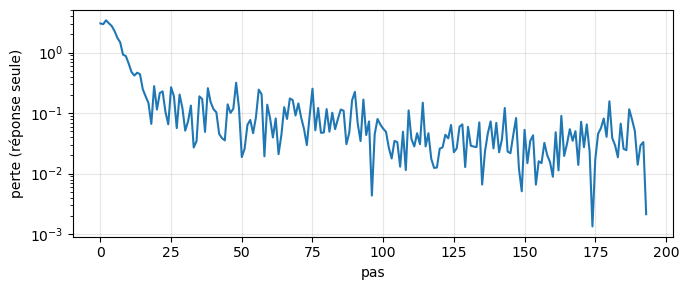

In [10]:
# Vérification du calcul A5 avec peft : rang 8 sur q, k, v, o (puis on retire cet adaptateur)
cfg = modele.config
hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
d_h, d_q, d_kv, d_ff, n_l = cfg.hidden_size, cfg.num_attention_heads * hd, cfg.num_key_value_heads * hd, cfg.intermediate_size, cfg.num_hidden_layers
attendu8 = n_l * 8 * ((d_h + d_q) + 2 * (d_h + d_kv) + (d_q + d_h))
essai = get_peft_model(modele, LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj", "k_proj", "v_proj", "o_proj"], task_type="CAUSAL_LM"))
n_essai = sum(p.numel() for p in essai.parameters() if p.requires_grad)
print(f"peft, rang 8 sur q, k, v, o : {n_essai:,} paramètres entraînables ; formule appliquée à ce modèle : {attendu8:,} ; calcul A5 (Qwen3-1.7B) : {total:,}".replace(",", " "),
      "- peft et formule concordent" if n_essai == attendu8 else "- DIFFÉRENT")
modele = essai.unload()
if hasattr(modele, "peft_config"):
    del modele.peft_config

modele.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
modele.enable_input_require_grads()
config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
modele_lora = get_peft_model(modele, config)
n_train = sum(p.numel() for p in modele_lora.parameters() if p.requires_grad)
n_tot = sum(p.numel() for p in modele_lora.parameters())
print(f"paramètres entraînables : {n_train:,} sur {n_tot:,}, soit {100 * n_train / n_tot:.2f} %".replace(",", " "))

formule = n_l * 16 * ((d_h + d_q) + (d_h + d_kv) * 2 + (d_q + d_h) + 3 * (d_h + d_ff))
print(f"formule r (d + k) sommée sur les 7 matrices x {n_l} couches : {formule:,}".replace(",", " "), "(identique)" if formule == n_train else "")

def cible_json(ligne):
    return json.dumps({"intent": ligne.intent, "slots": extraire_slots_ref(ligne.annot)}, ensure_ascii=False)

def exemple(ligne):
    p = tok(prompt_texte(SYSTEME_COURT, ligne.utt), add_special_tokens=False).input_ids
    r_ = tok(cible_json(ligne) + "<|im_end|>", add_special_tokens=False).input_ids
    return p + r_, [-100] * len(p) + r_

def lot_tensors(exemples):
    n = max(len(i) for i, _ in exemples)
    n = 32 * math.ceil(n / 32)            # peu de formes distinctes : MPS garde en mémoire un graphe compilé par forme
    ids = torch.full((len(exemples), n), tok.pad_token_id); lab = torch.full((len(exemples), n), -100); att = torch.zeros((len(exemples), n), dtype=torch.long)
    for k, (i, l) in enumerate(exemples):
        ids[k, :len(i)] = torch.tensor(i); lab[k, :len(l)] = torch.tensor(l); att[k, :len(i)] = 1
    return ids.to(DEVICE), lab.to(DEVICE), att.to(DEVICE)

N_TRAIN = len(tr) if DEVICE.type != "cpu" else 96
EPOQUES, LOT, LR = (2, 8, 2e-4) if DEVICE.type != "cpu" else (1, 8, 2e-4)
train_ex = [exemple(l) for l in tr.iloc[:N_TRAIN].itertuples()]
dev_ex = [exemple(l) for l in dv.itertuples()]
print(f"{len(train_ex)} exemples d'entraînement, {len(dev_ex)} de validation ; longueur moyenne {np.mean([len(i) for i, _ in train_ex]):.0f} tokens")
print("Exemple de cible :", cible_json(tr.iloc[0]))

def perte_dev():
    modele_lora.eval(); total, n = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(dev_ex), 16):
            ids, lab, att = lot_tensors(dev_ex[i:i + 16])
            total += modele_lora(input_ids=ids, attention_mask=att, labels=lab).loss.item() * len(ids); n += len(ids)
    return total / n

params = [p for p in modele_lora.parameters() if p.requires_grad]
opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.0)
n_pas = EPOQUES * math.ceil(len(train_ex) / LOT)
planif = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 10) * max(0.05, 1 - s / n_pas))
vider_cache()
print(f"perte de validation avant l'entraînement : {perte_dev():.3f}")
pertes, pas = [], 0
synchroniser(); t = time.time()
for ep in range(EPOQUES):
    modele_lora.train()
    ordre = list(range(len(train_ex))); random.Random(ep).shuffle(ordre)
    for i in range(0, len(ordre), LOT):
        ids, lab, att = lot_tensors([train_ex[j] for j in ordre[i:i + LOT]])
        perte = modele_lora(input_ids=ids, attention_mask=att, labels=lab).loss
        opt.zero_grad(); perte.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step(); planif.step()
        pertes.append(perte.item()); pas += 1
        if pas % 10 == 0:
            vider_cache()
        if pas % 20 == 0:
            print(f"  pas {pas:3d}/{n_pas} : perte {np.mean(pertes[-20:]):.4f}")
    print(f"fin de l'époque {ep + 1} : perte de validation {perte_dev():.3f}")
synchroniser(); DUREE_ENTR = time.time() - t
print(f"entraînement : {DUREE_ENTR:.0f} s ({DEVICE.type})")
fig, ax = plt.subplots(figsize=(7, 3)); ax.plot(pertes); ax.set_xlabel("pas"); ax.set_ylabel("perte (réponse seule)"); ax.set_yscale("log"); plt.tight_layout(); plt.show()

### B5. Comparer au zero-shot, sur les mêmes 220 commandes

On évalue le modèle fine-tuné avec le **prompt court**, puis le **même** modèle avec l'adaptateur **désactivé** (`disable_adapter`) : on isole l'effet de LoRA.

In [11]:
modele_lora.eval()
sor_ft, dur_ft, np_ft = evaluer(modele_lora, SYSTEME_COURT, te_eval.utt.tolist())
res_ft = resumer("LoRA, prompt court", sor_ft, dur_ft, np_ft, te_eval)
with modele_lora.disable_adapter():
    sor_off, dur_off, np_off = evaluer(modele_lora, SYSTEME_COURT, te_eval.utt.tolist())
res_off = resumer("même modèle, adaptateur désactivé", sor_off, dur_off, np_off, te_eval)
print()
res_zs = resumer("zero-shot, prompt long (Lab 6)", sor_zs, dur_zs, np_zs, te_eval)
print("\nSorties du modèle fine-tuné :")
for u, s, a in list(zip(te_eval.utt, sor_ft, te_eval.annot))[:4]:
    print(f"  « {u} »\n     -> {s.strip()}\n     attendu slots : {extraire_slots_ref(a)}")

LoRA, prompt court                 exactitude  93.2 %  | JSON invalide  0.0 %  | slots exacts  79.1 % (220 sorties avec slots) |    53 tokens de prompt |   60 s


même modèle, adaptateur désactivé  exactitude   0.0 %  | JSON invalide 100.0 %  | slots exacts   nan % (0 sorties avec slots) |    53 tokens de prompt |   52 s

zero-shot, prompt long (Lab 6)     exactitude  83.2 %  | JSON invalide  0.5 %  | slots exacts   nan % (0 sorties avec slots) |   200 tokens de prompt |   54 s

Sorties du modèle fine-tuné :
  « le rose est tout ce dont nous avons besoin »
     -> {"intent": "iot_hue_lighton", "slots": {}}
     attendu slots : {'color_type': 'rose'}
  « et l'obscurité est tombée »
     -> {"intent": "iot_hue_lighton", "slots": {}}
     attendu slots : {}
  « olly éteindre les lumières dans la chambre »
     -> {"intent": "iot_hue_lightoff", "slots": {"house_place": "chambre"}}
     attendu slots : {'house_place': 'chambre'}
  « c'est sale ici fais du bruit »
     -> {"intent": "iot_cleaning", "slots": {}}
     attendu slots : {}


In [12]:
lus = [lire_sortie(s) for s in sor_ft]
erreurs = collections.Counter((v, i) for (i, _), v in zip(lus, te_eval.intent) if i != v)
print("Confusions les plus fréquentes du modèle fine-tuné (vrai -> prédit) :")
for (v, i), n in erreurs.most_common(5):
    print(f"  {n:2d} x  {v:20s} -> {i}")
print(f"\nGain d'exactitude : {100 * (res_ft['acc'] - res_zs['acc']):+.1f} points ; prompt de {res_zs['n_prompt']:.0f} à {res_ft['n_prompt']:.0f} tokens "
      f"({res_zs['n_prompt'] / res_ft['n_prompt']:.1f} fois moins) ; adaptateur : {n_train / 1e6:.1f} M paramètres = {n_train * 4 / 1e6:.0f} Mo en float32.")
print("À comparer avec le GRU (Lab 4) et CamemBERT (Lab 5) sur les mêmes commandes iot_*.")

Confusions les plus fréquentes du modèle fine-tuné (vrai -> prédit) :
   3 x  iot_hue_lightdim     -> iot_hue_lightchange
   3 x  iot_hue_lightup      -> iot_hue_lighton
   2 x  iot_hue_lightchange  -> iot_hue_lighton
   2 x  iot_hue_lightup      -> iot_hue_lightchange
   2 x  iot_wemo_off         -> iot_hue_lightoff

Gain d'exactitude : +10.0 points ; prompt de 200 à 53 tokens (3.8 fois moins) ; adaptateur : 17.4 M paramètres = 70 Mo en float32.
À comparer avec le GRU (Lab 4) et CamemBERT (Lab 5) sur les mêmes commandes iot_*.


**À observer.** LoRA apprend surtout le **format** et le **vocabulaire d'étiquettes**, d'où un prompt court. Il ne rend pas le modèle plus « savant » : pour répondre sur une documentation qui change, le RAG (Lab 7a) reste le bon outil. Le coût d'un fine-tuning se paie une fois ; celui d'un long prompt se paie à **chaque requête**.

## Partie C — Exercices de validation

Chaque fonction ci-dessous renvoie `None` : le vérificateur affiche alors **« À compléter »**. Complétez-les, puis relancez `verifier_tout()`. Le corrigé est à la fin du notebook : essayez d'abord !

In [13]:
def verifier(nom, valeur, attendu, tol=1e-3):
    if valeur is None:
        print(f"{nom} : À compléter")
        return
    try:
        ok = np.allclose(np.asarray(valeur, dtype=float), np.asarray(attendu, dtype=float), atol=tol)
    except Exception:
        ok = False
    if ok:
        print(f"{nom} : Correct")
    else:
        print(f"{nom} : Incorrect (obtenu {np.round(np.asarray(valeur, dtype=float), 4)}, attendu {attendu})")

def verifier_egal(nom, valeur, attendu):
    if valeur is None:
        print(f"{nom} : À compléter")
    elif valeur == attendu:
        print(f"{nom} : Correct")
    else:
        print(f"{nom} : Incorrect (obtenu {valeur}, attendu {attendu})")

def verifier_tout():
    verifier("Exercice 1 — paramètres LoRA (4096, 4096, r = 8)", params_lora(4096, 4096, 8), 65536)
    verifier("Exercice 2 — W' = W + (alpha/r) B A", fusion_lora(np.array([[2.0, 0.0], [1.0, 3.0]]), np.array([[1.0], [2.0]]), np.array([[0.5, -1.0]]), 2.0, 1),
             [[3.0, -2.0], [3.0, -1.0]])
    verifier("Exercice 3 — gradient en B à l'initialisation", grad_B(np.array([1.0, 0.0]), np.array([1.0, 1.0]), np.array([[0.5, -1.0]]), 2.0, 1), [-1.0, 0.0])
    verifier("Exercice 4 — mémoire QLoRA d'un modèle de 7 B (Go)", memoire_qlora(7e9, 39976960), 4.2517, tol=0.01)
    verifier_egal("Exercice 5 — extraction des slots", extraire_slots("éteins la [device_type : lumière] de la [house_place : cuisine]"),
                  {"device_type": "lumière", "house_place": "cuisine"})

**Exercice 1 — Paramètres de LoRA.** Complétez `params_lora(d, k, r)` : le nombre de paramètres de $B$ et $A$.

In [14]:
def params_lora(d, k, r):
    # À compléter
    return None

**Exercice 2 — Fusion.** Complétez `fusion_lora(W, B, A, alpha, r)` : $W + \frac{\alpha}{r} BA$.

In [15]:
def fusion_lora(W, B, A, alpha, r):
    # À compléter
    return None

**Exercice 3 — Gradient en $B$.** Complétez `grad_B(delta, x, A, alpha, r)` : $\frac{\alpha}{r}\,\boldsymbol{\delta}\,(A\mathbf{x})$ avec $\boldsymbol{\delta}$ de taille $d$ et $A\mathbf{x}$ scalaire ($r = 1$). Renvoyez un vecteur de taille $d$.

In [16]:
def grad_B(delta, x, A, alpha, r):
    # À compléter
    return None

**Exercice 4 — Mémoire QLoRA.** Complétez `memoire_qlora(n_params, n_adaptateurs)` : poids en 4 bits (0,5 octet), constantes (0,127 bit par paramètre) et adaptateurs entraînés à 16 octets chacun. Renvoyez des **Go** ($10^9$ octets).

In [17]:
def memoire_qlora(n_params, n_adaptateurs):
    # À compléter
    return None

**Exercice 5 — Extraire les slots.** Complétez `extraire_slots(annot)` : renvoyez le dictionnaire `{nom: valeur}` des annotations `[nom : valeur]` d'une phrase MASSIVE (la première occurrence de chaque nom).

In [18]:
def extraire_slots(annot):
    # À compléter
    return None

verifier_tout()

Exercice 1 — paramètres LoRA (4096, 4096, r = 8) : À compléter
Exercice 2 — W' = W + (alpha/r) B A : À compléter
Exercice 3 — gradient en B à l'initialisation : À compléter
Exercice 4 — mémoire QLoRA d'un modèle de 7 B (Go) : À compléter
Exercice 5 — extraction des slots : À compléter


## Pour aller plus loin

- Faites varier le **rang** ($r = 2, 4, 8, 16, 32$) : l'exactitude et le nombre de paramètres évoluent comment ? À partir de quel rang ne gagne-t-on plus rien ?
- Ne ciblez que `q_proj` et `v_proj` (la configuration de l'article LoRA) : combien de paramètres entraînables, et quelle exactitude ?
- Entraînez sur **100 exemples** seulement : combien d'exemples faut-il pour apprendre le format ?
- Chargez le modèle en **4 bits** avec `bitsandbytes` (GPU CUDA) pour tester QLoRA, et comparez la mémoire mesurée à la formule.
- Après l'entraînement, **fusionnez** l'adaptateur (`modele_lora.merge_and_unload()`) et vérifiez que les sorties sont identiques.

## Références

- Hu et al. (2021), *LoRA: Low-Rank Adaptation of Large Language Models* ; Dettmers et al. (2023), *QLoRA* ; Houlsby et al. (2019), adaptateurs.
- FitzGerald et al. (2022), *MASSIVE* ; Qwen Team (2025), *Qwen3 technical report* ; bibliothèque Hugging Face `peft`.

## Corrigé

Essayez d'abord les exercices ! Cette section définit les solutions, puis relance le vérificateur.

In [19]:
def params_lora(d, k, r):
    return r * (d + k)

def fusion_lora(W, B, A, alpha, r):
    return W + (alpha / r) * (B @ A)

def grad_B(delta, x, A, alpha, r):
    return (alpha / r) * delta * float((A @ x).item())

def memoire_qlora(n_params, n_adaptateurs):
    return (n_params * 0.5 + n_params * 0.127 / 8 + n_adaptateurs * 16) / 1e9

def extraire_slots(annot):
    slots = {}
    for nom, valeur in re.findall(r"\[(\w+) : ([^\]]+)\]", annot):
        slots.setdefault(nom, valeur.strip())
    return slots

verifier_tout()

Exercice 1 — paramètres LoRA (4096, 4096, r = 8) : Correct
Exercice 2 — W' = W + (alpha/r) B A : Correct
Exercice 3 — gradient en B à l'initialisation : Correct
Exercice 4 — mémoire QLoRA d'un modèle de 7 B (Go) : Correct
Exercice 5 — extraction des slots : Correct


In [20]:
print(f"Durée d'exécution du notebook : {time.time() - T0:.0f} s")

Durée d'exécution du notebook : 720 s
